In [13]:
import numpy as np
import pandas as pd
from functools import reduce

import torch
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

import matplotlib as mpl
mpl.rc('text', usetex=False)

In [14]:
mean_Gradient0 = np.mean([0.0004, 0.0050, 0.00005, 0.0002, 0.0027])
mean_Adaptive0 = np.mean([0.0008,0.7898,0.0061,0.0000008,0.0121,0.00005,0.0018,0.0019,0.0012,0.0155,4.6496e-25,3.9716e-25])
mean_Polynomial0 = np.mean([0.001,1.3151,0.082,0.000009,0.0350,0.0006,0.0019,0.0018,0.0128,0.019,0.0020,3.1118e-08])
mean_Spectral0 = np.mean([0.2112,6.3855 ,0.0156,0.0934,14.1910,0.0155,26.536,14.1521,14.1521,0.0687,3975.5779,3283.7298])
mean_Inverse0 = np.mean([0.8751,206.6064,5.4783,0.4196,0.4601,0.0638,0.0017,0.0079,0.9548,3.5607,15075.2208,59.1723])
mean_Total0 = np.mean([0.7988,208.9618,6.2428,0.357,0.3273,0.0936,0.4919 ,0.4864,0.617,1.7065,15318.4098,68.1121])

mean_Gradient05 = np.mean([0.0048, 0.017, 0.0001,0.0002, 0.0024])
mean_Adaptive05 = np.mean([0.0009, 0.7936, 0.0061, 0.0041, 0.0221, 0.0001, 0.0111, 0.0115, 0.0013, 0.0154, 4.4623e-25, 4.4207e-25])
mean_Polynomial05 = np.mean([0.0206, 1.3864, 0.0832, 0.0009, 0.0366, 0.0006, 0.5938, 0.5695, 0.0129, 0.0188, 296.3631, 297.0768])
mean_Spectral05 = np.mean([0.2275, 6.4897, 0.0162, 0.0934, 14.1966, 0.0155, 28.7692, 17.0705, 0.0055, 0.0694, 5250.7934, 4299.9723])
mean_Inverse05 = np.mean([0.9018, 207.6153, 5.4904, 0.4195, 0.4617, 0.0638 ,72.7557, 2.4132, 0.952, 3.4523, 16376.1646, 1341.7407])
mean_Total05 = np.mean([0.8239, 209.9772, 6.2568, 0.3571, 0.3275, 0.0937, 2.932, 3.0227, 0.6166, 1.6975, 16622.2915, 1353.3664])

mean_Gradient1 = np.mean([0.018, 0.0502, 0.0003657, 0.0003, 0.0036])
mean_Adaptive1 = np.mean([0.1373, 2.3416, 0.0146, 0.0171, 0.0495, 0.0003, 0.0458, 0.0432, 0.0013, 0.0158, 4.4999e-25 ,4.9763e-25])
mean_Polynomial1 = np.mean([0.0474, 2.5502, 0.0868, 0.0034, 0.039, 0.00068, 2.6708, 2.6109, 0.0128, 0.0202, 1098.5015 ,1260.9454])
mean_Spectral1 = np.mean([0.2652, 7.2152, 0.02, 0.0941, 14.2271, 0.0154, 38.1629, 25.7555, 0.0057, 0.0694, 8281.9373, 9248.8831])
mean_Inverse1 = np.mean([0.9020, 207.6163, 5.4917, 0.4198, 0.4931, 0.0638, 46.8684, 47.1770, 0.9607, 3.1547, 19982.6044, 6108.153])
mean_Total1 = np.mean([0.8236, 209.9705, 6.2560, 0.3573, 0.3275, 0.0937, 12.0801, 11.3885, 12.0801, 11.3885, 20238.9430, 6130.2836])


In [15]:
#Gradient Adaptive Polynomial Spectral Inverse Total
mean_error_noise0 = np.log([mean_Gradient0, mean_Adaptive0, mean_Polynomial0, mean_Spectral0, mean_Inverse0, mean_Total0])

mean_error_noise05 = np.log([mean_Gradient05, mean_Adaptive05, mean_Polynomial05, mean_Spectral05, mean_Inverse05, mean_Total05])

mean_error_noise1 = np.log([mean_Gradient1, mean_Adaptive1, mean_Polynomial1, mean_Spectral1, mean_Inverse1, mean_Total1])

In [107]:
mean_error_noise0

array([-6.39493165, -2.67213929, -2.09882212,  6.4155236 ,  7.1541479 ,
        7.17054285])

In [108]:
mean_error_noise05

array([-5.31852007, -2.6285461 ,  3.90560781,  6.68645578,  7.31391076,
        7.32436708])

In [109]:
mean_error_noise1

array([-4.23407984, -1.5041399 ,  5.28467856,  7.29169316,  7.69636054,
        7.70503694])

In [16]:
#Gradient Adaptive Polynomial Spectral Inverse Total
shd_noise0 = [2,2,2,4,4,3]
shd_noise05 = [3,3,3,5,4,3]
shd_noise1 = [4,4,3,4,5,3]

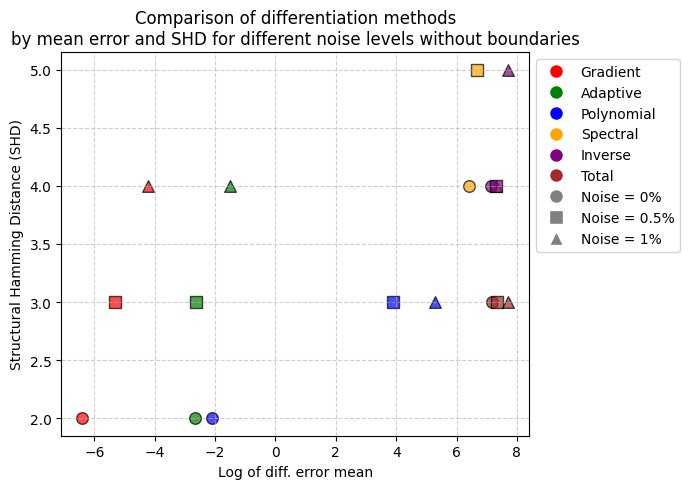

<Figure size 640x480 with 0 Axes>

In [17]:
#среднее по всем уранвениям
# Методы дифференцирования
methods = ['Gradient', 'Adaptive', 'Polynomial', 'Spectral', 'Inverse', 'Total']
colors = ['red', 'green', 'blue', 'orange', 'purple', 'brown']
markers = ['o', 's', '^']  # разные маркеры для разных уровней шума

# Создание графика
plt.figure(figsize=(7, 5))

# Построение точек для каждого метода
for i in range(6):
    # Точки для разных уровней шума
    plt.scatter(mean_error_noise0[i], shd_noise0[i], color=colors[i], s=70, 
                label=methods[i], marker=markers[0], alpha=0.7, 
            edgecolors='black')
    plt.scatter(mean_error_noise05[i], shd_noise05[i], color=colors[i], s=70, 
                marker=markers[1], alpha=0.7, 
            edgecolors='black')
    plt.scatter(mean_error_noise1[i], shd_noise1[i], color=colors[i], s=70, 
                marker=markers[2], alpha=0.7, 
            edgecolors='black')

# Настройка графика
plt.xlabel('Log of diff. error mean', fontsize=10)
plt.ylabel('Structural Hamming Distance (SHD)', fontsize=10)
plt.title('Comparison of differentiation methods\nby mean error and SHD for different noise levels without boundaries', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# Создание кастомной легенды
legend_elements = []

# Добавляем элементы для методов
for i in range(6):
    legend_elements.append(plt.Line2D([0], [0], marker='o', color='w', label=methods[i],
                          markerfacecolor=colors[i], markersize=10))

# Добавляем элементы для уровней шума
legend_elements.append(plt.Line2D([0], [0], marker=markers[0], color='w', label='Noise = 0%',
                      markerfacecolor='gray',  markersize=10))
legend_elements.append(plt.Line2D([0], [0], marker=markers[1], color='w', label='Noise = 0.5%',
                      markerfacecolor='gray', markersize=10))
legend_elements.append(plt.Line2D([0], [0], marker=markers[2], color='w', label='Noise = 1%',
                      markerfacecolor='gray', markersize=10))

plt.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()
plt.savefig('Comparison_error_SHD_without_bond.pdf', format='pdf')


In [18]:
mean_Gradient0 = np.mean([0.0002, 0.0030, 0.00004, 0.0017, 0.0302])
mean_Adaptive0 = np.mean([0.0010, 0.4113, 0.0047, 0.00005, 0.0058, 0.00005, 0.0219, 0.1528, 0.0230 ,0.4480 ,3.9068, 2.4417])
mean_Polynomial0 = np.mean([0.0014 ,0.9714, 0.0639, 0.0001,0.0168, 0.0003,0.0093, 0.0052, 0.0422 ,0.0518 ,0.0009, 1.3527e-08])
mean_Spectral0 = np.mean([13.1979 ,20.9399 ,0.1296, 1.3950, 14.2714, 0.0105, 265.6624, 153.8350, 0.2305 ,0.6544 ,4330.2841 ,4791.3391])
mean_Inverse0 = np.mean([0.6641 ,105.0296, 3.9091, 0.2128 ,0.1948 ,0.0325, 0.0170 ,0.3305 ,1.1393, 4.7208 ,6552.9687 ,25.7213])
mean_Total0 = np.mean([0.5659, 106.5467 ,4.4983 ,0.2416 ,0.2002 ,0.0687 ,1.6339, 1.4325, 0.8787, 2.2920 ,9867.9392, 663.3597])

mean_Gradient05 = np.mean([0.0047, 0.0076, 0.00006, 0.0021, 0.0345])
mean_Adaptive05 = np.mean([0.0082, 0.4425 ,0.0046, 0.0026, 0.0088 ,0.00007 ,7.1115, 10.3365 ,0.0227 ,0.4455, 106.6517, 1796.4747])
mean_Polynomial05 = np.mean([0.0259, 2.1655, 0.0651, 0.0031, 0.0620 ,0.0003 ,72.4688, 79.1133 ,0.0415 ,0.0704 ,83.3851 ,130.6980])
mean_Spectral05 = np.mean([13.1257 ,21.0673, 0.1299, 1.3961, 14.2823, 0.0105, 287.4326 ,190.3073 ,0.2324, 0.6584 ,5164.4719 ,5031.0763])
mean_Inverse05 = np.mean([0.7112 ,105.4608, 3.9048 ,0.2145,0.1951, 0.0324, 5887.0620, 806.0344 ,1.1366 ,12.4026, 7255.2930 ,433.5565])
mean_Total05 = np.mean([0.6153, 106.9564, 4.4938, 0.2418 ,0.2001, 0.0688, 21.0357, 27.2037, 0.8829, 2.299, 10748.5392, 5073.4548])

mean_Gradient1 = np.mean([0.0326, 0.0315, 0.0002, 0.0033, 0.0429])
mean_Adaptive1 = np.mean([0.0241, 0.5434 ,0.0048, 0.0134, 0.0248, 0.0002 ,28.9184, 19.6306, 0.0278, 0.4711, 405.1010, 8660.7907])
mean_Polynomial1 = np.mean([0.0740, 5.2326, 0.0660, 0.0170, 0.1662 ,0.0003 ,238.2998 ,231.4645 ,0.0498, 0.0922 ,665.12100 ,472.6915])
mean_Spectral1 = np.mean([13.2611 ,21.4309 ,0.1311 ,1.3969, 14.2965, 0.0105, 351.0565, 219.6478, 0.2334, 0.6601, 6266.4304, 7554.8468])
mean_Inverse1 = np.mean([0.8143 ,106.2819, 3.9179, 0.2131, 0.2346, 0.0326 ,8770.9156, 178600.1116, 1.1606, 23.7757 ,8576.6807, 2610.7530])
mean_Total1 = np.mean([0.7134, 107.7962 ,4.5084, 0.2419, 0.2002 ,0.0687 ,83.6729 ,57.0657, 0.8796 ,2.2926 ,15496.6550, 24050.0412])


In [19]:
#Gradient Adaptive Polynomial Spectral Inverse Total
mean_error_noise0 = np.log([mean_Gradient0, mean_Adaptive0, mean_Polynomial0, mean_Spectral0, mean_Inverse0, mean_Total0])

mean_error_noise05 = np.log([mean_Gradient05, mean_Adaptive05, mean_Polynomial05, mean_Spectral05, mean_Inverse05, mean_Total05])

mean_error_noise1 = np.log([mean_Gradient1, mean_Adaptive1, mean_Polynomial1, mean_Spectral1, mean_Inverse1, mean_Total1])

In [9]:
mean_error_noise0


array([-4.95785311, -0.4811185 , -2.33364584,  6.68377281,  6.32420072,
        6.78837635])

In [20]:
#Gradient Adaptive Polynomial Spectral Inverse Total
shd_noise0 = [2,2,2,4,4,3]
shd_noise05 = [3,3,3,5,4,3]
shd_noise1 = [4,4,3,4,5,3]

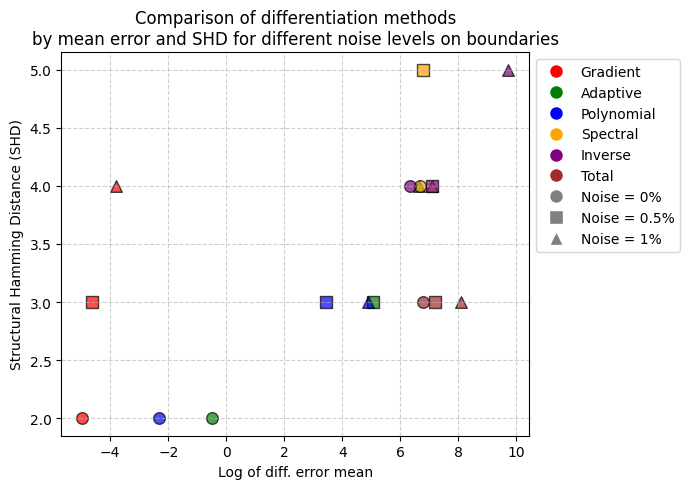

<Figure size 640x480 with 0 Axes>

In [21]:
# Методы дифференцирования
methods = ['Gradient', 'Adaptive', 'Polynomial', 'Spectral', 'Inverse', 'Total']
colors = ['red', 'green', 'blue', 'orange', 'purple', 'brown']
markers = ['o', 's', '^']  # разные маркеры для разных уровней шума

# Создание графика
plt.figure(figsize=(7, 5))

# Построение точек для каждого метода
for i in range(6):
    # Точки для разных уровней шума
    plt.scatter(mean_error_noise0[i], shd_noise0[i], color=colors[i], s=70, 
                label=methods[i], marker=markers[0], alpha=0.7, 
            edgecolors='black')
    plt.scatter(mean_error_noise05[i], shd_noise05[i], color=colors[i], s=70, 
                marker=markers[1], alpha=0.7, 
            edgecolors='black')
    plt.scatter(mean_error_noise1[i], shd_noise1[i], color=colors[i], s=70, 
                marker=markers[2], alpha=0.7, 
            edgecolors='black')

# Настройка графика
plt.xlabel('Log of diff. error mean', fontsize=10)
plt.ylabel('Structural Hamming Distance (SHD)', fontsize=10)
plt.title('Comparison of differentiation methods\nby mean error and SHD for different noise levels on boundaries', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# Создание кастомной легенды
legend_elements = []

# Добавляем элементы для методов
for i in range(6):
    legend_elements.append(plt.Line2D([0], [0], marker='o', color='w', label=methods[i],
                          markerfacecolor=colors[i], markersize=10))

# Добавляем элементы для уровней шума
legend_elements.append(plt.Line2D([0], [0], marker=markers[0], color='w', label='Noise = 0%',
                      markerfacecolor='gray',  markersize=10))
legend_elements.append(plt.Line2D([0], [0], marker=markers[1], color='w', label='Noise = 0.5%',
                      markerfacecolor='gray', markersize=10))
legend_elements.append(plt.Line2D([0], [0], marker=markers[2], color='w', label='Noise = 1%',
                      markerfacecolor='gray', markersize=10))

plt.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()
plt.savefig('Comparison_error_SHD_on_bond.pdf', format='pdf')


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Данные для уравнения Бюргерса
#среднее по всем слагаемым для разных методов (5 методов) для нулевого шума
mean_Adaptive0_b = np.mean([0.0008, 0.7898, 0.0061]) 
mean_Polynomial0_b = np.mean([0.001, 1.3151, 0.082])
mean_Spectral0_b = np.mean([0.2112, 6.3855, 0.0156])
mean_Inverse0_b = np.mean([0.8751, 206.6064, 5.4783])
mean_Total0_b = np.mean([0.7988, 208.9618, 6.2428])

#среднее по всем слагаемым для разных методов (5 методов) для шума = 0.5
mean_Adaptive05_b = np.mean([0.0009, 0.7936, 0.0061])
mean_Polynomial05_b = np.mean([0.0206, 1.3864, 0.08328])
mean_Spectral05_b = np.mean([0.2275, 6.4897, 0.0162])
mean_Inverse05_b = np.mean([0.9018, 207.6153, 5.4904])
mean_Total05_b = np.mean([0.8239, 209.9772, 6.2568])

#среднее по всем слагаемым для разных методов (5 методов) для шума = 1
mean_Adaptive1_b = np.mean([0.1373, 2.3416, 0.0146])
mean_Polynomial1_b = np.mean([0.0474, 2.5502, 0.0868])
mean_Spectral1_b = np.mean([0.2652, 7.2152, 0.02])
mean_Inverse1_b = np.mean([0.9020, 207.6163, 5.4917])
mean_Total1_b = np.mean([0.8236, 209.9705, 6.2560])

#берем логарифм для лучшей отрисовки
error_b0 = np.log([mean_Adaptive0_b, mean_Polynomial0_b, mean_Spectral0_b, mean_Inverse0_b, mean_Total0_b])
error_b05 = np.log([mean_Adaptive05_b, mean_Polynomial05_b, mean_Spectral05_b, mean_Inverse05_b, mean_Total05_b])
error_b1 = np.log([mean_Adaptive1_b, mean_Polynomial1_b, mean_Spectral1_b, mean_Inverse1_b, mean_Total1_b])

#коэфф SHD
shd_b0 = [6,4,6,6,6]#слева направо коэфф SHD для методов Adaptive Polynomial Spectral Inverse Total при нулевом шуме 
shd_b05 = [7,4,6,6,5]#слева направо коэфф SHD для методов Adaptive Polynomial Spectral Inverse Total при шуме =0.5
shd_b1 = [7,4,6,6,6]#слева направо коэфф SHD для методов Adaptive Polynomial Spectral Inverse Total при нулевом =1

# Аналогично данные для уравнения Коргевега де Фриза , только здесь 6 методов
mean_Gradient0_k = np.mean([0.0004, 0.0050, 0.00005])
mean_Adaptive0_k = np.mean([0.0000008,0.0121,0.00005])
mean_Polynomial0_k = np.mean([0.000009,0.0350,0.0006])
mean_Spectral0_k = np.mean([0.0934,14.1910,0.0155])
mean_Inverse0_k = np.mean([5.4783,0.4196,0.4601])
mean_Total0_k = np.mean([0.357,0.3273,0.0936])

mean_Gradient05_k = np.mean([0.0048, 0.017, 0.0001])
mean_Adaptive05_k = np.mean([0.0041, 0.0221, 0.0001])
mean_Polynomial05_k = np.mean([0.0009, 0.0366, 0.0006])
mean_Spectral05_k = np.mean([0.0934, 14.1966, 0.0155])
mean_Inverse05_k = np.mean([0.4195, 0.4617, 0.0638])
mean_Total05_k = np.mean([0.3571, 0.3275, 0.0937])

mean_Gradient1_k = np.mean([0.018, 0.0502, 0.0003657])
mean_Adaptive1_k = np.mean([0.0171, 0.0495, 0.0003])
mean_Polynomial1_k = np.mean([0.0034, 0.039, 0.00068])
mean_Spectral1_k = np.mean([0.0941, 14.2271, 0.0154])
mean_Inverse1_k = np.mean([0.4198, 0.4931, 0.0638])
mean_Total1_k = np.mean([0.3573, 0.3275, 0.0937])

error_k0 = np.log([mean_Gradient0_k, mean_Adaptive0_k, mean_Polynomial0_k, 
                  mean_Spectral0_k, mean_Inverse0_k, mean_Total0_k])
error_k05 = np.log([mean_Gradient05_k, mean_Adaptive05_k, mean_Polynomial05_k,
                   mean_Spectral05_k, mean_Inverse05_k, mean_Total05_k])
error_k1 = np.log([mean_Gradient1_k, mean_Adaptive1_k, mean_Polynomial1_k,
                  mean_Spectral1_k, mean_Inverse1_k, mean_Total1_k])

shd_k0 = [3,3,3,6,4,4]
shd_k05 = [5,3,5,7,5,5]
shd_k1 = [6,4,6,7,7,5]

# Аналогично данные для уравнения Лапласа , только здесь 5 методов

mean_Adaptive0_l = np.mean([0.0018,0.0019])
mean_Polynomial0_l = np.mean([0.0019, 0.0018])
mean_Spectral0_l = np.mean([26.536, 14.1521])
mean_Inverse0_l = np.mean([0.0017, 0.0079])
mean_Total0_l = np.mean([0.4919, 0.4864])


mean_Adaptive05_l = np.mean([0.0111, 0.0115])
mean_Polynomial05_l = np.mean([0.5938, 0.5695])
mean_Spectral05_l = np.mean([28.7692, 17.0705])
mean_Inverse05_l = np.mean([72.7557, 2.4132])
mean_Total05_l = np.mean([2.932, 3.0227])


mean_Adaptive1_l = np.mean([0.0458, 0.0432])
mean_Polynomial1_l = np.mean([2.6708, 2.6109])
mean_Spectral1_l = np.mean([38.1629, 25.7555])
mean_Inverse1_l = np.mean([46.8684, 47.1770])
mean_Total1_l = np.mean([12.0801, 11.3885])

error_l0 = np.log([mean_Adaptive0_l, mean_Polynomial0_l, 
                  mean_Spectral0_l, mean_Inverse0_l, mean_Total0_l])
error_l05 = np.log([mean_Adaptive05_l, mean_Polynomial05_l,
                   mean_Spectral05_l, mean_Inverse05_l, mean_Total05_l])
error_l1 = np.log([mean_Adaptive1_l, mean_Polynomial1_l,
                  mean_Spectral1_l, mean_Inverse1_l, mean_Total1_l])

shd_l0 = [0,0,3,2,2]
shd_l05 = [2,2,3,3,2]
shd_l1 = [2,2,3,2,2]

# Аналогично данные для уравнения ОДУ , только здесь 6 методов

mean_Gradient0_o = np.mean([0.0002, 0.0027])
mean_Adaptive0_o = np.mean([0.0012, 0.0155])
mean_Polynomial0_o = np.mean([0.0128, 0.019])
mean_Spectral0_o = np.mean([0.0056, 0.0687])
mean_Inverse0_o = np.mean([0.9548, 3.5607])
mean_Total0_o = np.mean([0.617, 1.7065])

mean_Gradient05_o = np.mean([0.0002, 0.0024])
mean_Adaptive05_o = np.mean([0.0013 ,0.0154])
mean_Polynomial05_o = np.mean([0.0129, 0.0188])
mean_Spectral05_o = np.mean([0.0055, 0.0694])
mean_Inverse05_o = np.mean([0.952 ,3.4523])
mean_Total05_o = np.mean([0.6166 ,1.6975])

mean_Gradient1_o = np.mean([0.0003, 0.0036])
mean_Adaptive1_o = np.mean([0.0013, 0.0158])
mean_Polynomial1_o = np.mean([0.0128, 0.0202])
mean_Spectral1_o = np.mean([0.0057 ,0.0694])
mean_Inverse1_o = np.mean([0.9607, 3.1547])
mean_Total1_o = np.mean([0.6155 ,1.7163])

error_o0 = np.log([mean_Gradient0_o, mean_Adaptive0_o, mean_Polynomial0_o, 
                  mean_Spectral0_o, mean_Inverse0_o, mean_Total0_o])
error_o05 = np.log([mean_Gradient05_o, mean_Adaptive05_o, mean_Polynomial05_o,
                   mean_Spectral05_o, mean_Inverse05_o, mean_Total05_o])
error_o1 = np.log([mean_Gradient1_o, mean_Adaptive1_o, mean_Polynomial1_o,
                  mean_Spectral1_o, mean_Inverse1_o, mean_Total1_o])

shd_o0 = [0,0,0,3,4,0]
shd_o05 = [0,0,0,3,4,0]
shd_o1 = [0,0,0,3,4,0]

# Аналогично данные для уравнения Коргевега де Фриза , только здесь 4 метода


mean_Polynomial0_w = np.mean([0.0020 ,3.1118e-08])
mean_Spectral0_w = np.mean([3975.5779, 3283.7298])
mean_Inverse0_w = np.mean([15075.2208, 59.1723])
mean_Total0_w = np.mean([15318.4098, 68.1121])


#mean_Adaptive05_w = np.mean([4.4623e-25 ,4.4207e-25])
mean_Polynomial05_w = np.mean([296.3631, 297.0768])
mean_Spectral05_w = np.mean([5250.7934, 4299.9723])
mean_Inverse05_w = np.mean([16376.1646, 1341.7407])
mean_Total05_w = np.mean([16622.2915, 1353.3664])



mean_Polynomial1_w = np.mean([1098.5015 ,1260.9454])
mean_Spectral1_w = np.mean([8281.9373, 9248.8831])
mean_Inverse1_w = np.mean([19982.6044, 6108.153])
mean_Total1_w = np.mean([20238.9430 ,6130.2836])

error_w0 = np.log([  mean_Polynomial0_w, 
                  mean_Spectral0_w, mean_Inverse0_w, mean_Total0_w])
error_w05 = np.log([ mean_Polynomial05_w,
                   mean_Spectral05_w, mean_Inverse05_w, mean_Total05_w])
error_w1 = np.log([  mean_Polynomial1_w,
                  mean_Spectral1_w, mean_Inverse1_w, mean_Total1_w])

shd_w0 = [1,1,4,3,2]
shd_w05 = [4,4,4,3,2]
shd_w1 = [5,4,3,4,2]


<Figure size 900x500 with 0 Axes>

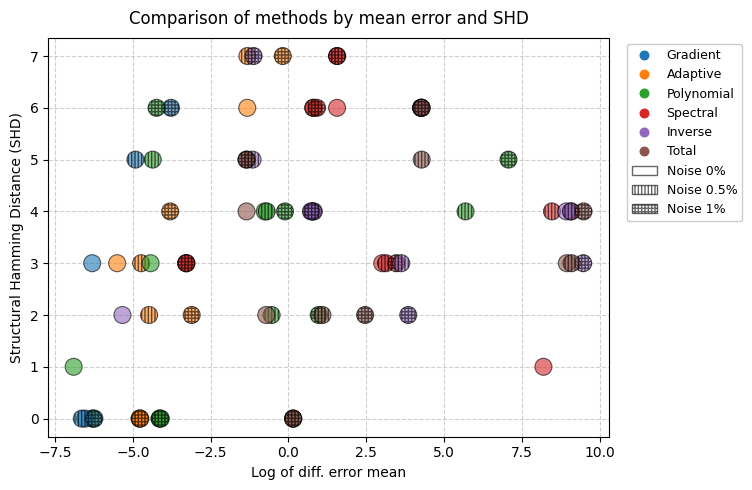

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

#среднее по каждому уравнению
# Настройки визуализации
plt.figure(figsize=(9, 5))

# Цвета для методов (первые 5 цветов для Burgers, 6 цветов для KdV)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

# Методы (объединенный список)
methods_b = ['Adaptive', 'Polynomial', 'Spectral', 'Inverse', 'Total']
methods_k = ['Gradient', 'Adaptive', 'Polynomial', 'Spectral', 'Inverse', 'Total']
methods_l = ['Adaptive', 'Polynomial', 'Spectral', 'Inverse', 'Total']
methods_o = ['Gradient', 'Adaptive', 'Polynomial', 'Spectral', 'Inverse', 'Total']
methods_w = ['Polynomial', 'Spectral', 'Inverse', 'Total']



hatch_style_0 = ''
hatch_style_05 = '|||||'  # Вертикальная штриховка для 0.5%
hatch_style_1 = '+++++'    # Перекрестная штриховка для 1%

# Параметры стиля
marker_size = 150
edge_width = 0.8
alpha_value = 0.6

# Создаем фигуру и оси
fig, ax = plt.subplots(figsize=(9, 5))

# Рисуем ВСЕ точки как кружки без различий между уравнениями
for i in range(5):  # Методы Burgers (5 методов)
    # noise 0%
    ax.scatter(error_b0[i], shd_b0[i], color=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_0, zorder=3)
    # noise 0.5%
    ax.scatter(error_b05[i], shd_b05[i], facecolor=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_05, zorder=3)
    # noise 1%
    ax.scatter(error_b1[i], shd_b1[i], facecolor=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_1, zorder=3)

for i in range(6):  # Методы KdV (6 методов)
    # noise 0%
    ax.scatter(error_k0[i], shd_k0[i], color=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_0, zorder=3)
    # noise 0.5%
    ax.scatter(error_k05[i], shd_k05[i], facecolor=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_05, zorder=3)
    # noise 1%
    ax.scatter(error_k1[i], shd_k1[i], facecolor=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_1, zorder=3)

# Рисуем ВСЕ точки как кружки без различий между уравнениями
for i in range(5):  # Методы Laplace (5 методов)
    # noise 0%
    ax.scatter(error_l0[i], shd_l0[i], color=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_0, zorder=3)
    # noise 0.5%
    ax.scatter(error_l05[i], shd_l05[i], facecolor=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_05, zorder=3)
    # noise 1%
    ax.scatter(error_l1[i], shd_l1[i], facecolor=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_1, zorder=3)
   
for i in range(6):  # Методы ODE (6 методов)
    # noise 0%
    ax.scatter(error_o0[i], shd_o0[i], color=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_0, zorder=3)
    # noise 0.5%
    ax.scatter(error_o05[i], shd_o05[i], facecolor=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_05, zorder=3)
    # noise 1%
    ax.scatter(error_o1[i], shd_o1[i], facecolor=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_1, zorder=3)
   
for i in range(4):  # Методы Wave (4 методов)
    # noise 0%
    ax.scatter(error_w0[i], shd_w0[i], color=colors[i+2], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_0, zorder=3)
    # noise 0.5%
    ax.scatter(error_w05[i], shd_w05[i], facecolor=colors[i+2], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_05, zorder=3)
    # noise 1%
    ax.scatter(error_w1[i], shd_w1[i], facecolor=colors[i+2], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_1, zorder=3)
   
# Настройка осей
ax.set_xlabel('Log of diff. error mean', fontsize=10)
ax.set_ylabel('Structural Hamming Distance (SHD)', fontsize=10)
ax.set_title('Comparison of methods by mean error and SHD', fontsize=12, pad=10)
ax.grid(True, linestyle='--', alpha=0.6, zorder=0)

# Упрощенная легенда (только методы и уровни шума)
legend_elements = [
    # Методы (цветные круги)
    *[Line2D([0], [0], marker='o', color='w', label=methods_k[i],
       markerfacecolor=colors[i], markersize=8, markeredgewidth=0.8) 
      for i in range(6)],
    
    # Уровни шума (штриховка)
    Patch(facecolor='white', edgecolor='black', label='Noise 0%', alpha=alpha_value),
    Patch(facecolor='white', edgecolor='black', label='Noise 0.5%', 
          hatch=hatch_style_05, alpha=alpha_value),
    Patch(facecolor='white', edgecolor='black', label='Noise 1%', 
          hatch=hatch_style_1, alpha=alpha_value)]

# Размещаем легенду
ax.legend(handles=legend_elements, loc='upper left', 
          bbox_to_anchor=(1.02, 1), fontsize=9, framealpha=1)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

In [9]:
# Данные для уравнения Бюргерса
#среднее по всем слагаемым для разных методов (5 методов) для нулевого шума
mean_Adaptive0_b = np.mean([0.0009 ,0.05902, 0.0053]) 
mean_Polynomial0_b = np.mean([0.0012 ,1.1339, 0.0724])
mean_Spectral0_b = np.mean([7.0597, 14.0607 ,0.0757])
mean_Inverse0_b = np.mean([0.7638, 153.0405 ,4.6508])
mean_Total0_b = np.mean([0.6760 ,154.9538, 5.3229])

#среднее по всем слагаемым для разных методов (5 методов) для шума = 0.5
mean_Adaptive05_b = np.mean([0.0048, 0.6084, 0.0053])
mean_Polynomial05_b = np.mean([0.0234 ,1.7973, 0.0737])
mean_Spectral05_b = np.mean([7.0293, 14.1771, 0.0761])
mean_Inverse05_b = np.mean([0.8013, 153.7448 ,4.6542])
mean_Total05_b = np.mean([0.7139, 155.6498 ,5.3271])

#среднее по всем слагаемым для разных методов (5 методов) для шума = 1
mean_Adaptive1_b = np.mean([0.1311, 1.9259, 0.0121])
mean_Polynomial1_b = np.mean([0.088 ,3.5219 ,0.0761])
mean_Spectral1_b = np.mean([7.1244 ,14.7814, 0.0783])
mean_Inverse1_b = np.mean([0.8933 ,154.1399 ,4.6562])
mean_Total1_b = np.mean([0.8085, 156.0558, 5.3286])

#берем логарифм для лучшей отрисовки
error_b0 = np.log([mean_Adaptive0_b, mean_Polynomial0_b, mean_Spectral0_b, mean_Inverse0_b, mean_Total0_b])
error_b05 = np.log([mean_Adaptive05_b, mean_Polynomial05_b, mean_Spectral05_b, mean_Inverse05_b, mean_Total05_b])
error_b1 = np.log([mean_Adaptive1_b, mean_Polynomial1_b, mean_Spectral1_b, mean_Inverse1_b, mean_Total1_b])

#коэфф SHD
shd_b0 = [6,4,6,6,6]#слева направо коэфф SHD для методов Adaptive Polynomial Spectral Inverse Total при нулевом шуме 
shd_b05 = [7,4,6,6,5]#слева направо коэфф SHD для методов Adaptive Polynomial Spectral Inverse Total при шуме =0.5
shd_b1 = [7,4,6,6,6]#слева направо коэфф SHD для методов Adaptive Polynomial Spectral Inverse Total при нулевом =1

# Аналогично данные для уравнения Коргевега де Фриза , только здесь 6 методов
mean_Gradient0_k = np.mean([0.000329, 0.0039 ,0.00004184])
mean_Adaptive0_k = np.mean([0.00001 ,0.0088, 0.00005])
mean_Polynomial0_k = np.mean([0.00007761, 0.0254, 0.0004532])
mean_Spectral0_k = np.mean([0.7798, 14.2334, 0.0129])
mean_Inverse0_k = np.mean([0.3105, 0.3202 ,0.0473])
mean_Total0_k = np.mean([0.357, 0.3275 ,0.0937])

mean_Gradient05_k = np.mean([0.00478, 0.0120, 0.0000947])
mean_Adaptive05_k = np.mean([0.0033, 0.0151, 0.0001])
mean_Polynomial05_k = np.mean([0.0021 ,0.05, 0.0004592])
mean_Spectral05_k = np.mean([0.7804, 14.2418, 0.0128])
mean_Inverse05_k = np.mean([0.3114, 0.3211, 0.0473])
mean_Total05_k = np.mean([0.3571 ,0.3275, 0.0937])

mean_Gradient1_k = np.mean([0.0260, 0.0403, 0.0002695])
mean_Adaptive1_k = np.mean([0.01521 ,0.0365, 0.0003])
mean_Polynomial1_k = np.mean([0.0106, 0.1061 ,0.000499])
mean_Spectral1_k = np.mean([0.7811, 14.2637, 0.0129])
mean_Inverse1_k = np.mean([0.3108 ,0.3568, 0.0473])
mean_Total1_k = np.mean([0.3573 ,0.3273, 0.0936])

error_k0 = np.log([mean_Gradient0_k, mean_Adaptive0_k, mean_Polynomial0_k, 
                  mean_Spectral0_k, mean_Inverse0_k, mean_Total0_k])
error_k05 = np.log([mean_Gradient05_k, mean_Adaptive05_k, mean_Polynomial05_k,
                   mean_Spectral05_k, mean_Inverse05_k, mean_Total05_k])
error_k1 = np.log([mean_Gradient1_k, mean_Adaptive1_k, mean_Polynomial1_k,
                  mean_Spectral1_k, mean_Inverse1_k, mean_Total1_k])

shd_k0 = [3,3,3,6,4,4]
shd_k05 = [5,3,5,7,5,5]
shd_k1 = [6,4,6,7,7,5]

# Аналогично данные для уравнения Лапласа , только здесь 5 методов

mean_Adaptive0_l = np.mean([0.0124, 0.0814])
mean_Polynomial0_l = np.mean([0.0058 ,0.0036])
mean_Spectral0_l = np.mean([152.6378, 87.813])
mean_Inverse0_l = np.mean([0.0098, 0.178])
mean_Total0_l = np.mean([1.0941, 0.9853])


mean_Adaptive05_l = np.mean([3.7555 ,5.4563])
mean_Polynomial05_l = np.mean([38.4966, 41.9891])
mean_Spectral05_l = np.mean([165.1737 ,108.4259])
mean_Inverse05_l = np.mean([3138.8939 ,426.1978])
mean_Total05_l = np.mean([12.4789 ,15.7744])


mean_Adaptive1_l = np.mean([15.2715, 10.3725])
mean_Polynomial1_l = np.mean([126.9283 ,123.2955])
mean_Spectral1_l = np.mean([203.1654, 128.0034])
mean_Inverse1_l = np.mean([4647.4401, 94205.9511])
mean_Total1_l = np.mean([49.8341 ,35.4761])

error_l0 = np.log([mean_Adaptive0_l, mean_Polynomial0_l, 
                  mean_Spectral0_l, mean_Inverse0_l, mean_Total0_l])
error_l05 = np.log([mean_Adaptive05_l, mean_Polynomial05_l,
                   mean_Spectral05_l, mean_Inverse05_l, mean_Total05_l])
error_l1 = np.log([mean_Adaptive1_l, mean_Polynomial1_l,
                  mean_Spectral1_l, mean_Inverse1_l, mean_Total1_l])

shd_l0 = [0,0,3,2,2]
shd_l05 = [2,2,3,3,2]
shd_l1 = [2,2,3,2,2]

# Аналогично данные для уравнения ОДУ , только здесь 6 методов

mean_Gradient0_o = np.mean([0.00067 ,0.0113])
mean_Adaptive0_o = np.mean([0.00801 ,0.1507])
mean_Polynomial0_o = np.mean([0.022 ,0.0292])
mean_Spectral0_o = np.mean([0.0759 ,0.2517])
mean_Inverse0_o = np.mean([1.1231, 3.9290])
mean_Total0_o = np.mean([0.6988 ,1.8895])

mean_Gradient05_o = np.mean([0.00081, 0.0124])
mean_Adaptive05_o = np.mean([0.008 ,0.1498])
mean_Polynomial05_o = np.mean([0.0218, 0.0349])
mean_Spectral05_o = np.mean([0.0764, 0.2534])
mean_Inverse05_o = np.mean([1.1220, 6.2318])
mean_Total05_o = np.mean([0.6998 ,1.8857])

mean_Gradient1_o = np.mean([0.00122 ,0.0160])
mean_Adaptive1_o = np.mean([0.0096 ,0.1609])
mean_Polynomial1_o = np.mean([0.0241, 0.0416])
mean_Spectral1_o = np.mean([0.0771, 0.2538])
mean_Inverse1_o = np.mean([1.132 ,9.6419])
mean_Total1_o = np.mean([0.6993 ,1.9013])

error_o0 = np.log([mean_Gradient0_o, mean_Adaptive0_o, mean_Polynomial0_o, 
                  mean_Spectral0_o, mean_Inverse0_o, mean_Total0_o])
error_o05 = np.log([mean_Gradient05_o, mean_Adaptive05_o, mean_Polynomial05_o,
                   mean_Spectral05_o, mean_Inverse05_o, mean_Total05_o])
error_o1 = np.log([mean_Gradient1_o, mean_Adaptive1_o, mean_Polynomial1_o,
                  mean_Spectral1_o, mean_Inverse1_o, mean_Total1_o])

shd_o0 = [0,0,0,3,4,0]
shd_o05 = [0,0,0,3,4,0]
shd_o1 = [0,0,0,3,4,0]

# Аналогично данные для уравнения волнового , только здесь 5 метода

mean_Adaptive0_w = np.mean([2.0602, 1.2876])
mean_Polynomial0_w = np.mean([9.8417 ,0.0057])
mean_Spectral0_w = np.mean([87251.4516 ,32328.7991])
mean_Inverse0_w = np.mean([12282.1612, 47.9087])
mean_Total0_w = np.mean([12444.1383, 65.6059])


mean_Adaptive05_w = np.mean([56.2421, 947.3597])
mean_Polynomial05_w = np.mean([3047.6637, 13167.1760])
mean_Spectral05_w = np.mean([87963.7107, 36937.9071])
mean_Inverse05_w = np.mean([13359.6413, 3287.3561])
mean_Total05_w = np.mean([13524.8049 ,3315.1318])


mean_Adaptive1_w = np.mean([213.6322, 4567.2138])
mean_Polynomial1_w = np.mean([10740.0809 ,57619.2452])
mean_Spectral1_w = np.mean([92107.8232 ,44231.8631])
mean_Inverse1_w = np.mean([17561.9236, 15300.6987])
mean_Total1_w = np.mean([17738.1271, 15580.1558])

error_w0 = np.log([ mean_Adaptive0_w, mean_Polynomial0_w, 
                  mean_Spectral0_w, mean_Inverse0_w, mean_Total0_w])
error_w05 = np.log([mean_Adaptive05_w ,mean_Polynomial05_w,
                   mean_Spectral05_w, mean_Inverse05_w, mean_Total05_w])
error_w1 = np.log([ mean_Adaptive1_w ,mean_Polynomial1_w,
                  mean_Spectral1_w, mean_Inverse1_w, mean_Total1_w])

shd_w0 = [1,1,4,3,2]
shd_w05 = [4,4,4,3,2]
shd_w1 = [5,4,3,4,2]


<Figure size 900x500 with 0 Axes>

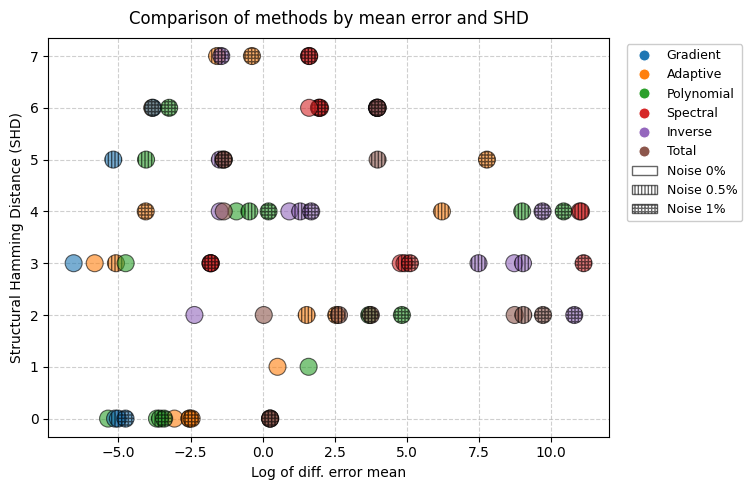

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Настройки визуализации
plt.figure(figsize=(9, 5))

# Цвета для методов (первые 5 цветов для Burgers, 6 цветов для KdV)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

# Методы (объединенный список)
methods_b = ['Adaptive', 'Polynomial', 'Spectral', 'Inverse', 'Total']
methods_k = ['Gradient', 'Adaptive', 'Polynomial', 'Spectral', 'Inverse', 'Total']
methods_l = ['Adaptive', 'Polynomial', 'Spectral', 'Inverse', 'Total']
methods_o = ['Gradient', 'Adaptive', 'Polynomial', 'Spectral', 'Inverse', 'Total']
methods_w = ['Adaptive','Polynomial', 'Spectral', 'Inverse', 'Total']



hatch_style_0 = ''
hatch_style_05 = '|||||'  # Вертикальная штриховка для 0.5%
hatch_style_1 = '+++++'    # Перекрестная штриховка для 1%

# Параметры стиля
marker_size = 150
edge_width = 0.8
alpha_value = 0.6

# Создаем фигуру и оси
fig, ax = plt.subplots(figsize=(9, 5))

# Рисуем ВСЕ точки как кружки без различий между уравнениями
for i in range(5):  # Методы Burgers (5 методов)
    # noise 0%
    ax.scatter(error_b0[i], shd_b0[i], color=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_0, zorder=3)
    # noise 0.5%
    ax.scatter(error_b05[i], shd_b05[i], facecolor=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_05, zorder=3)
    # noise 1%
    ax.scatter(error_b1[i], shd_b1[i], facecolor=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_1, zorder=3)

for i in range(6):  # Методы KdV (6 методов)
    # noise 0%
    ax.scatter(error_k0[i], shd_k0[i], color=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_0, zorder=3)
    # noise 0.5%
    ax.scatter(error_k05[i], shd_k05[i], facecolor=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_05, zorder=3)
    # noise 1%
    ax.scatter(error_k1[i], shd_k1[i], facecolor=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_1, zorder=3)

# Рисуем ВСЕ точки как кружки без различий между уравнениями
for i in range(5):  # Методы Laplace (5 методов)
    # noise 0%
    ax.scatter(error_l0[i], shd_l0[i], color=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_0, zorder=3)
    # noise 0.5%
    ax.scatter(error_l05[i], shd_l05[i], facecolor=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_05, zorder=3)
    # noise 1%
    ax.scatter(error_l1[i], shd_l1[i], facecolor=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_1, zorder=3)
   
for i in range(6):  # Методы ODE (6 методов)
    # noise 0%
    ax.scatter(error_o0[i], shd_o0[i], color=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_0, zorder=3)
    # noise 0.5%
    ax.scatter(error_o05[i], shd_o05[i], facecolor=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_05, zorder=3)
    # noise 1%
    ax.scatter(error_o1[i], shd_o1[i], facecolor=colors[i], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_1, zorder=3)
   
for i in range(5):  # Методы Wave (4 методов)
    # noise 0%
    ax.scatter(error_w0[i], shd_w0[i], color=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_0, zorder=3)
    # noise 0.5%
    ax.scatter(error_w05[i], shd_w05[i], facecolor=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_05, zorder=3)
    # noise 1%
    ax.scatter(error_w1[i], shd_w1[i], facecolor=colors[i+1], s=marker_size,
               edgecolor='black', linewidth=edge_width, alpha=alpha_value,
               marker='o', hatch=hatch_style_1, zorder=3)
   
# Настройка осей
ax.set_xlabel('Log of diff. error mean', fontsize=10)
ax.set_ylabel('Structural Hamming Distance (SHD)', fontsize=10)
ax.set_title('Comparison of methods by mean error and SHD', fontsize=12, pad=10)
ax.grid(True, linestyle='--', alpha=0.6, zorder=0)

# Упрощенная легенда (только методы и уровни шума)
legend_elements = [
    # Методы (цветные круги)
    *[Line2D([0], [0], marker='o', color='w', label=methods_k[i],
       markerfacecolor=colors[i], markersize=8, markeredgewidth=0.8) 
      for i in range(6)],
    
    # Уровни шума (штриховка)
    Patch(facecolor='white', edgecolor='black', label='Noise 0%', alpha=alpha_value),
    Patch(facecolor='white', edgecolor='black', label='Noise 0.5%', 
          hatch=hatch_style_05, alpha=alpha_value),
    Patch(facecolor='white', edgecolor='black', label='Noise 1%', 
          hatch=hatch_style_1, alpha=alpha_value)]

# Размещаем легенду
ax.legend(handles=legend_elements, loc='upper left', 
          bbox_to_anchor=(1.02, 1), fontsize=9, framealpha=1)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

    Noise      Method  SHD  diff error
0     0.0    Adaptive    6    0.021740
1     0.5    Adaptive    7    0.206167
2     1.0    Adaptive    7    0.689700
3     0.0  Polynomial    4    0.402500
4     0.5  Polynomial    4    0.631467
5     1.0  Polynomial    4    1.228667
6     0.0    Spectral    6    7.065367
7     0.5    Spectral    6    7.094167
8     1.0    Spectral    6    7.328033
9     0.0     Inverse    6   52.818367
10    0.5     Inverse    6   53.066767
11    1.0     Inverse    6   53.229800
12    0.0   Total_var    6   53.650900
13    0.5   Total_var    5   53.896933
14    1.0   Total_var    6   54.064300
SHD ~ Noise: r = 0.087, p = 0.759
Error ~ Noise: r = 0.008, p = 0.976
SHD ~ Error: r = 0.163, p = 0.561


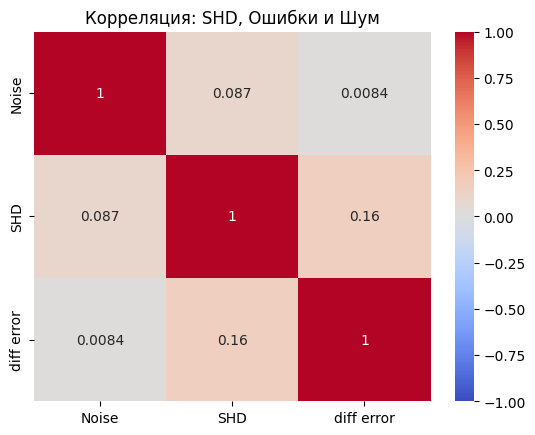

In [17]:
import pandas as pd
from scipy.stats import pearsonr
import seaborn as sns
import matplotlib.pyplot as plt

# Данные SHD (Burgers)
data_shd = {
    'Noise': [0, 0.5, 1] * 5,
    'Method': ['Adaptive']*3 + ['Polynomial']*3 + 
              ['Spectral']*3 + ['Inverse']*3 + ['Total_var']*3,
    'SHD': [6, 7, 7, 4, 4, 4, 6, 6, 6, 6, 6, 6, 6, 5, 6]
}
df_shd = pd.DataFrame(data_shd)

# Данные ошибок (Burgers)
# Данные для уравнения Бюргерса
#среднее по всем слагаемым для разных методов (5 методов) для нулевого шума
mean_Adaptive0_b = np.mean([0.0009 ,0.05902, 0.0053]) 
mean_Polynomial0_b = np.mean([0.0012 ,1.1339, 0.0724])
mean_Spectral0_b = np.mean([7.0597, 14.0607 ,0.0757])
mean_Inverse0_b = np.mean([0.7638, 153.0405 ,4.6508])
mean_Total0_b = np.mean([0.6760 ,154.9538, 5.3229])

#среднее по всем слагаемым для разных методов (5 методов) для шума = 0.5
mean_Adaptive05_b = np.mean([0.0048, 0.6084, 0.0053])
mean_Polynomial05_b = np.mean([0.0234 ,1.7973, 0.0737])
mean_Spectral05_b = np.mean([7.0293, 14.1771, 0.0761])
mean_Inverse05_b = np.mean([0.8013, 153.7448 ,4.6542])
mean_Total05_b = np.mean([0.7139, 155.6498 ,5.3271])

#среднее по всем слагаемым для разных методов (5 методов) для шума = 1
mean_Adaptive1_b = np.mean([0.1311, 1.9259, 0.0121])
mean_Polynomial1_b = np.mean([0.088 ,3.5219 ,0.0761])
mean_Spectral1_b = np.mean([7.1244 ,14.7814, 0.0783])
mean_Inverse1_b = np.mean([0.8933 ,154.1399 ,4.6562])
mean_Total1_b = np.mean([0.8085, 156.0558, 5.3286])

data_errors = {
    'Noise': [0, 0.5, 1] * 5,
    'Method': ['Adaptive']*3 + ['Polynomial']*3 + ['Spectral']*3 + 
              ['Inverse']*3 + ['Total_var']*3,
    'diff error': [mean_Adaptive0_b, mean_Adaptive05_b, mean_Adaptive1_b, mean_Polynomial0_b, mean_Polynomial05_b, mean_Polynomial1_b, 
                    mean_Spectral0_b, mean_Spectral05_b, mean_Spectral1_b, mean_Inverse0_b, mean_Inverse05_b, mean_Inverse1_b, 
                    mean_Total0_b, mean_Total05_b, mean_Total1_b]
}
df_errors = pd.DataFrame(data_errors)

# объединение данных
df_combined = pd.merge(df_shd, df_errors, on=['Method', 'Noise'], how='left')
print(df_combined)
# корреляция
corr_shd_noise, p_shd_noise = pearsonr(df_combined['Noise'], df_combined['SHD'])
corr_error_noise, p_error_noise = pearsonr(df_combined['Noise'], df_combined['diff error'])
corr_shd_error, p_shd_error = pearsonr(df_combined['SHD'], df_combined['diff error'])

print(f"SHD ~ Noise: r = {corr_shd_noise:.3f}, p = {p_shd_noise:.3f}")
print(f"Error ~ Noise: r = {corr_error_noise:.3f}, p = {p_error_noise:.3f}")
print(f"SHD ~ Error: r = {corr_shd_error:.3f}, p = {p_shd_error:.3f}")

# Визуализация
corr_matrix = df_combined[['Noise', 'SHD', 'diff error']].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляция: SHD, Ошибки и Шум")
plt.show()

    Noise      Method  SHD  diff error
0     0.0    Gradient    3    0.001424
1     0.5    Gradient    5    0.005625
2     1.0    Gradient    6    0.022190
3     0.0    Adaptive    3    0.002953
4     0.5    Adaptive    3    0.006167
5     1.0    Adaptive    4    0.017337
6     0.0  Polynomial    3    0.008644
7     0.5  Polynomial    5    0.017520
8     1.0  Polynomial    6    0.039066
9     0.0    Spectral    6    5.008700
10    0.5    Spectral    7    5.011667
11    1.0    Spectral    7    5.019233
12    0.0     Inverse    4    0.226000
13    0.5     Inverse    5    0.226600
14    1.0     Inverse    7    0.238300
15    0.0   Total_var    4    0.259400
16    0.5   Total_var    5    0.259433
17    1.0   Total_var    5    0.259400
SHD ~ Noise: r = 0.596, p = 0.009
Error ~ Noise: r = 0.003, p = 0.990
SHD ~ Error: r = 0.596, p = 0.009


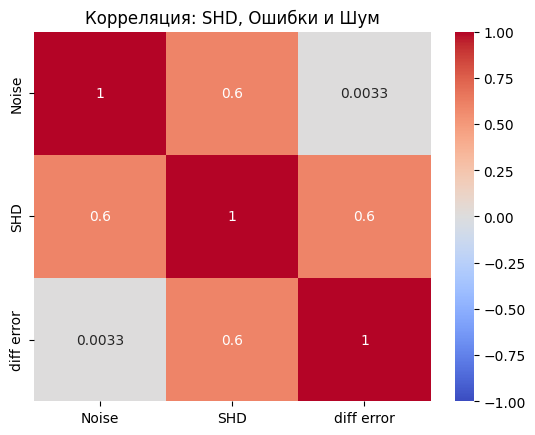

In [13]:
import pandas as pd
from scipy.stats import pearsonr
import seaborn as sns
import matplotlib.pyplot as plt

# Данные SHD (Burgers)
data_shd = {
    'Noise': [0, 0.5, 1] * 6,
    'Method': ['Gradient']*3 + ['Adaptive']*3 + ['Polynomial']*3 + 
              ['Spectral']*3 + ['Inverse']*3 + ['Total_var']*3,
    'SHD': [3, 5, 6, 3, 3, 4, 3, 5, 6, 6, 7, 7, 4, 5, 7, 4, 5 ,5]
}
df_shd = pd.DataFrame(data_shd)

data_errors = {
    'Noise': [0, 0.5, 1] * 6,
    'Method': ['Gradient']*3 + ['Adaptive']*3 + ['Polynomial']*3 + ['Spectral']*3 + 
              ['Inverse']*3 + ['Total_var']*3,
    'diff error': [mean_Gradient0_k, mean_Gradient05_k, mean_Gradient1_k, mean_Adaptive0_k, mean_Adaptive05_k, mean_Adaptive1_k, mean_Polynomial0_k, mean_Polynomial05_k, mean_Polynomial1_k, 
                    mean_Spectral0_k, mean_Spectral05_k, mean_Spectral1_k, mean_Inverse0_k, mean_Inverse05_k, mean_Inverse1_k, 
                    mean_Total0_k, mean_Total05_k, mean_Total1_k]
}
df_errors = pd.DataFrame(data_errors)

# объединение данных
df_combined = pd.merge(df_shd, df_errors, on=['Method', 'Noise'], how='left')
print(df_combined)
# корреляция
corr_shd_noise, p_shd_noise = pearsonr(df_combined['Noise'], df_combined['SHD'])
corr_error_noise, p_error_noise = pearsonr(df_combined['Noise'], df_combined['diff error'])
corr_shd_error, p_shd_error = pearsonr(df_combined['SHD'], df_combined['diff error'])

print(f"SHD ~ Noise: r = {corr_shd_noise:.3f}, p = {p_shd_noise:.3f}")
print(f"Error ~ Noise: r = {corr_error_noise:.3f}, p = {p_error_noise:.3f}")
print(f"SHD ~ Error: r = {corr_shd_error:.3f}, p = {p_shd_error:.3f}")

# Визуализация
corr_matrix = df_combined[['Noise', 'SHD', 'diff error']].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляция: SHD, Ошибки и Шум")
plt.show()

    Noise      Method  SHD   diff error
0     0.0    Adaptive    0      0.04690
1     0.5    Adaptive    2      4.60590
2     1.0    Adaptive    2     12.82200
3     0.0  Polynomial    0      0.00470
4     0.5  Polynomial    2     40.24285
5     1.0  Polynomial    2    125.11190
6     0.0    Spectral    3    120.22540
7     0.5    Spectral    3    136.79980
8     1.0    Spectral    3    165.58440
9     0.0     Inverse    2      0.09390
10    0.5     Inverse    3   1782.54585
11    1.0     Inverse    2  49426.69560
12    0.0   Total_var    2      1.03970
13    0.5   Total_var    2     14.12665
14    1.0   Total_var    2     42.65510
SHD ~ Noise: r = 0.365, p = 0.181
Error ~ Noise: r = 0.330, p = 0.230
SHD ~ Error: r = 0.013, p = 0.962


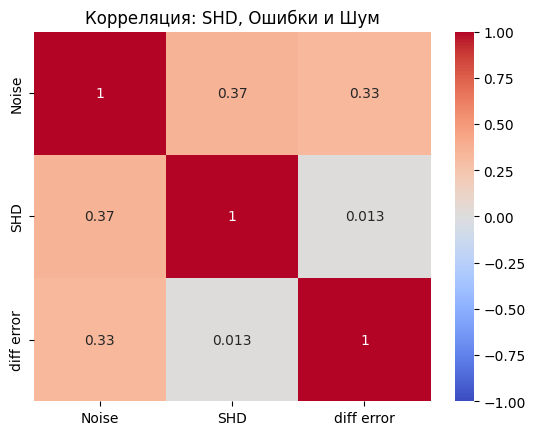

In [14]:
import pandas as pd
from scipy.stats import pearsonr
import seaborn as sns
import matplotlib.pyplot as plt

# Данные SHD (Burgers)
data_shd = {
    'Noise': [0, 0.5, 1] * 5,
    'Method': ['Adaptive']*3 + ['Polynomial']*3 + 
              ['Spectral']*3 + ['Inverse']*3 + ['Total_var']*3,
    'SHD': [0,2,2,0,2,2,3, 3, 3, 2, 3, 2, 2, 2, 2]
}
df_shd = pd.DataFrame(data_shd)

# Данные ошибок (Burgers)
# Данные для уравнения Бюргерса
#среднее по всем слагаемым для разных методов (5 методов) для нулевого шума
mean_Adaptive0_b = np.mean([0.0009 ,0.05902, 0.0053]) 
mean_Polynomial0_b = np.mean([0.0012 ,1.1339, 0.0724])
mean_Spectral0_b = np.mean([7.0597, 14.0607 ,0.0757])
mean_Inverse0_b = np.mean([0.7638, 153.0405 ,4.6508])
mean_Total0_b = np.mean([0.6760 ,154.9538, 5.3229])

#среднее по всем слагаемым для разных методов (5 методов) для шума = 0.5
mean_Adaptive05_b = np.mean([0.0048, 0.6084, 0.0053])
mean_Polynomial05_b = np.mean([0.0234 ,1.7973, 0.0737])
mean_Spectral05_b = np.mean([7.0293, 14.1771, 0.0761])
mean_Inverse05_b = np.mean([0.8013, 153.7448 ,4.6542])
mean_Total05_b = np.mean([0.7139, 155.6498 ,5.3271])

#среднее по всем слагаемым для разных методов (5 методов) для шума = 1
mean_Adaptive1_b = np.mean([0.1311, 1.9259, 0.0121])
mean_Polynomial1_b = np.mean([0.088 ,3.5219 ,0.0761])
mean_Spectral1_b = np.mean([7.1244 ,14.7814, 0.0783])
mean_Inverse1_b = np.mean([0.8933 ,154.1399 ,4.6562])
mean_Total1_b = np.mean([0.8085, 156.0558, 5.3286])

data_errors = {
    'Noise': [0, 0.5, 1] * 5,
    'Method': ['Adaptive']*3 + ['Polynomial']*3 + ['Spectral']*3 + 
              ['Inverse']*3 + ['Total_var']*3,
    'diff error': [mean_Adaptive0_l, mean_Adaptive05_l, mean_Adaptive1_l, mean_Polynomial0_l, mean_Polynomial05_l, mean_Polynomial1_l, 
                    mean_Spectral0_l, mean_Spectral05_l, mean_Spectral1_l, mean_Inverse0_l, mean_Inverse05_l, mean_Inverse1_l, 
                    mean_Total0_l, mean_Total05_l, mean_Total1_l]
}
df_errors = pd.DataFrame(data_errors)

# объединение данных
df_combined = pd.merge(df_shd, df_errors, on=['Method', 'Noise'], how='left')
print(df_combined)
# корреляция
corr_shd_noise, p_shd_noise = pearsonr(df_combined['Noise'], df_combined['SHD'])
corr_error_noise, p_error_noise = pearsonr(df_combined['Noise'], df_combined['diff error'])
corr_shd_error, p_shd_error = pearsonr(df_combined['SHD'], df_combined['diff error'])

print(f"SHD ~ Noise: r = {corr_shd_noise:.3f}, p = {p_shd_noise:.3f}")
print(f"Error ~ Noise: r = {corr_error_noise:.3f}, p = {p_error_noise:.3f}")
print(f"SHD ~ Error: r = {corr_shd_error:.3f}, p = {p_shd_error:.3f}")

# Визуализация
corr_matrix = df_combined[['Noise', 'SHD', 'diff error']].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляция: SHD, Ошибки и Шум")
plt.show()

    Noise      Method  SHD  diff error
0     0.0    Gradient    0    0.005985
1     0.5    Gradient    0    0.006605
2     1.0    Gradient    0    0.008610
3     0.0    Adaptive    0    0.079355
4     0.5    Adaptive    0    0.078900
5     1.0    Adaptive    0    0.085250
6     0.0  Polynomial    0    0.025600
7     0.5  Polynomial    0    0.028350
8     1.0  Polynomial    0    0.032850
9     0.0    Spectral    3    0.163800
10    0.5    Spectral    3    0.164900
11    1.0    Spectral    3    0.165450
12    0.0     Inverse    4    2.526050
13    0.5     Inverse    4    3.676900
14    1.0     Inverse    4    5.386950
15    0.0   Total_var    0    1.294150
16    0.5   Total_var    0    1.292750
17    1.0   Total_var    0    1.300300
SHD ~ Noise: r = 0.000, p = 1.000
Error ~ Noise: r = 0.133, p = 0.599
SHD ~ Error: r = 0.647, p = 0.004


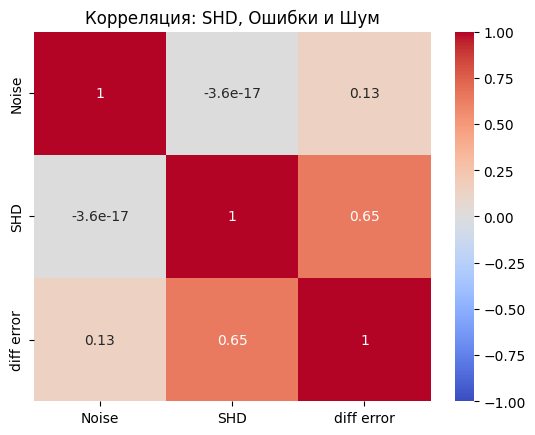

In [15]:
import pandas as pd
from scipy.stats import pearsonr
import seaborn as sns
import matplotlib.pyplot as plt

# Данные SHD (Burgers)
data_shd = {
    'Noise': [0, 0.5, 1] * 6,
    'Method': ['Gradient']*3 + ['Adaptive']*3 + ['Polynomial']*3 + 
              ['Spectral']*3 + ['Inverse']*3 + ['Total_var']*3,
    'SHD': [0,0,0,0,0,0,0,0,0,3,3,3,4,4,4,0,0,0]
}
df_shd = pd.DataFrame(data_shd)

data_errors = {
    'Noise': [0, 0.5, 1] * 6,
    'Method': ['Gradient']*3 +  ['Adaptive']*3 + ['Polynomial']*3 + ['Spectral']*3 + 
              ['Inverse']*3 + ['Total_var']*3,
    'diff error': [mean_Gradient0_o, mean_Gradient05_o, mean_Gradient1_o,mean_Adaptive0_o, mean_Adaptive05_o, mean_Adaptive1_o, mean_Polynomial0_o, mean_Polynomial05_o, mean_Polynomial1_o, 
                    mean_Spectral0_o, mean_Spectral05_o, mean_Spectral1_o, mean_Inverse0_o, mean_Inverse05_o, mean_Inverse1_o, 
                    mean_Total0_o, mean_Total05_o, mean_Total1_o]
}
df_errors = pd.DataFrame(data_errors)

# объединение данных
df_combined = pd.merge(df_shd, df_errors, on=['Method', 'Noise'], how='left')
print(df_combined)
# корреляция
corr_shd_noise, p_shd_noise = pearsonr(df_combined['Noise'], df_combined['SHD'])
corr_error_noise, p_error_noise = pearsonr(df_combined['Noise'], df_combined['diff error'])
corr_shd_error, p_shd_error = pearsonr(df_combined['SHD'], df_combined['diff error'])

print(f"SHD ~ Noise: r = {corr_shd_noise:.3f}, p = {p_shd_noise:.3f}")
print(f"Error ~ Noise: r = {corr_error_noise:.3f}, p = {p_error_noise:.3f}")
print(f"SHD ~ Error: r = {corr_shd_error:.3f}, p = {p_shd_error:.3f}")

# Визуализация
corr_matrix = df_combined[['Noise', 'SHD', 'diff error']].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляция: SHD, Ошибки и Шум")
plt.show()

    Noise      Method  SHD   diff error
0     0.0    Adaptive    1      1.67390
1     0.5    Adaptive    4    501.80090
2     1.0    Adaptive    5   2390.42300
3     0.0  Polynomial    1      4.92370
4     0.5  Polynomial    4   8107.41985
5     1.0  Polynomial    4  34179.66305
6     0.0    Spectral    4  59790.12535
7     0.5    Spectral    4  62450.80890
8     1.0    Spectral    3  68169.84315
9     0.0     Inverse    3   6165.03495
10    0.5     Inverse    3   8323.49870
11    1.0     Inverse    4  16431.31115
12    0.0   Total_var    2   6254.87210
13    0.5   Total_var    2   8419.96835
14    1.0   Total_var    2  16659.14145
SHD ~ Noise: r = 0.484, p = 0.068
Error ~ Noise: r = 0.229, p = 0.412
SHD ~ Error: r = 0.326, p = 0.236


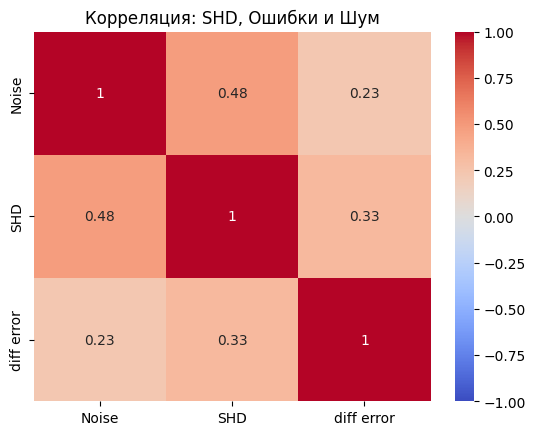

In [16]:
import pandas as pd
from scipy.stats import pearsonr
import seaborn as sns
import matplotlib.pyplot as plt

# Данные SHD (Burgers)
data_shd = {
    'Noise': [0, 0.5, 1] * 5,
    'Method': ['Adaptive']*3 + ['Polynomial']*3 + 
              ['Spectral']*3 + ['Inverse']*3 + ['Total_var']*3,
    'SHD': [1,4,5,1,4,4,4,4,3,3,3,4,2,2,2]
}
df_shd = pd.DataFrame(data_shd)


data_errors = {
    'Noise': [0, 0.5, 1] * 5,
    'Method': ['Adaptive']*3 + ['Polynomial']*3 + ['Spectral']*3 + 
              ['Inverse']*3 + ['Total_var']*3,
    'diff error': [mean_Adaptive0_w, mean_Adaptive05_w, mean_Adaptive1_w, mean_Polynomial0_w, mean_Polynomial05_w, mean_Polynomial1_w, 
                    mean_Spectral0_w, mean_Spectral05_w, mean_Spectral1_w, mean_Inverse0_w, mean_Inverse05_w, mean_Inverse1_w, 
                    mean_Total0_w, mean_Total05_w, mean_Total1_w]
}
df_errors = pd.DataFrame(data_errors)

# объединение данных
df_combined = pd.merge(df_shd, df_errors, on=['Method', 'Noise'], how='left')
print(df_combined)
# корреляция
corr_shd_noise, p_shd_noise = pearsonr(df_combined['Noise'], df_combined['SHD'])
corr_error_noise, p_error_noise = pearsonr(df_combined['Noise'], df_combined['diff error'])
corr_shd_error, p_shd_error = pearsonr(df_combined['SHD'], df_combined['diff error'])

print(f"SHD ~ Noise: r = {corr_shd_noise:.3f}, p = {p_shd_noise:.3f}")
print(f"Error ~ Noise: r = {corr_error_noise:.3f}, p = {p_error_noise:.3f}")
print(f"SHD ~ Error: r = {corr_shd_error:.3f}, p = {p_shd_error:.3f}")

# Визуализация
corr_matrix = df_combined[['Noise', 'SHD', 'diff error']].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляция: SHD, Ошибки и Шум")
plt.show()